# **Multi-Agent Planner with MCP**
![Multi-Agent Travel Planner img-1.png](<attachment:Multi-Agent Travel Planner img-1.png>)

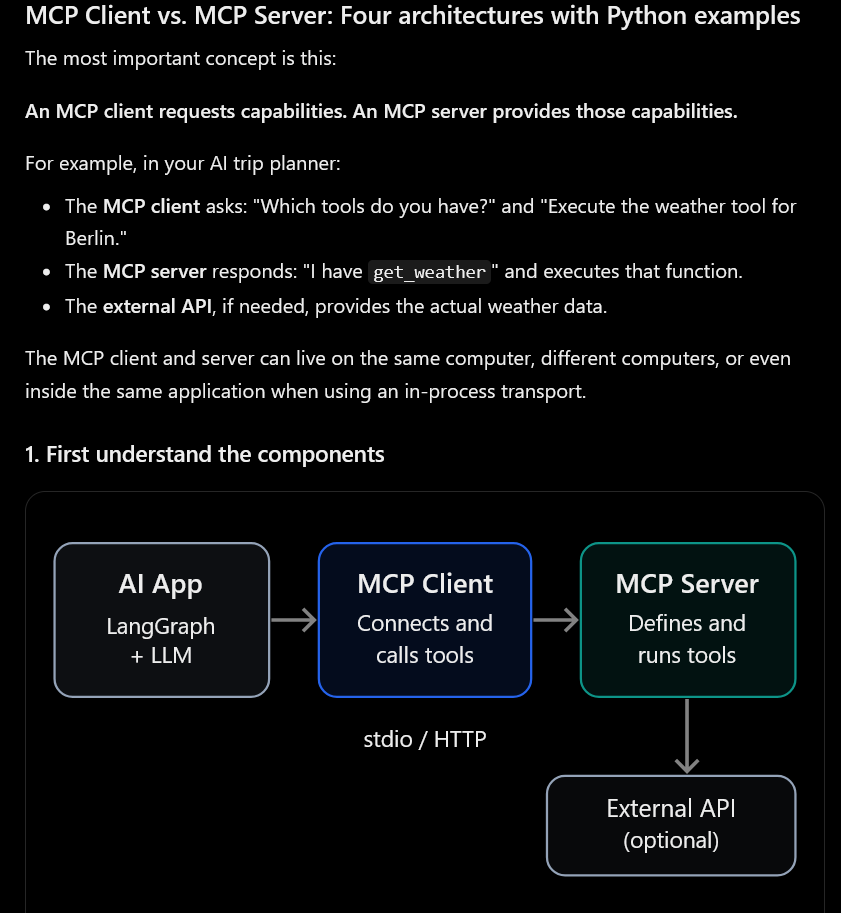
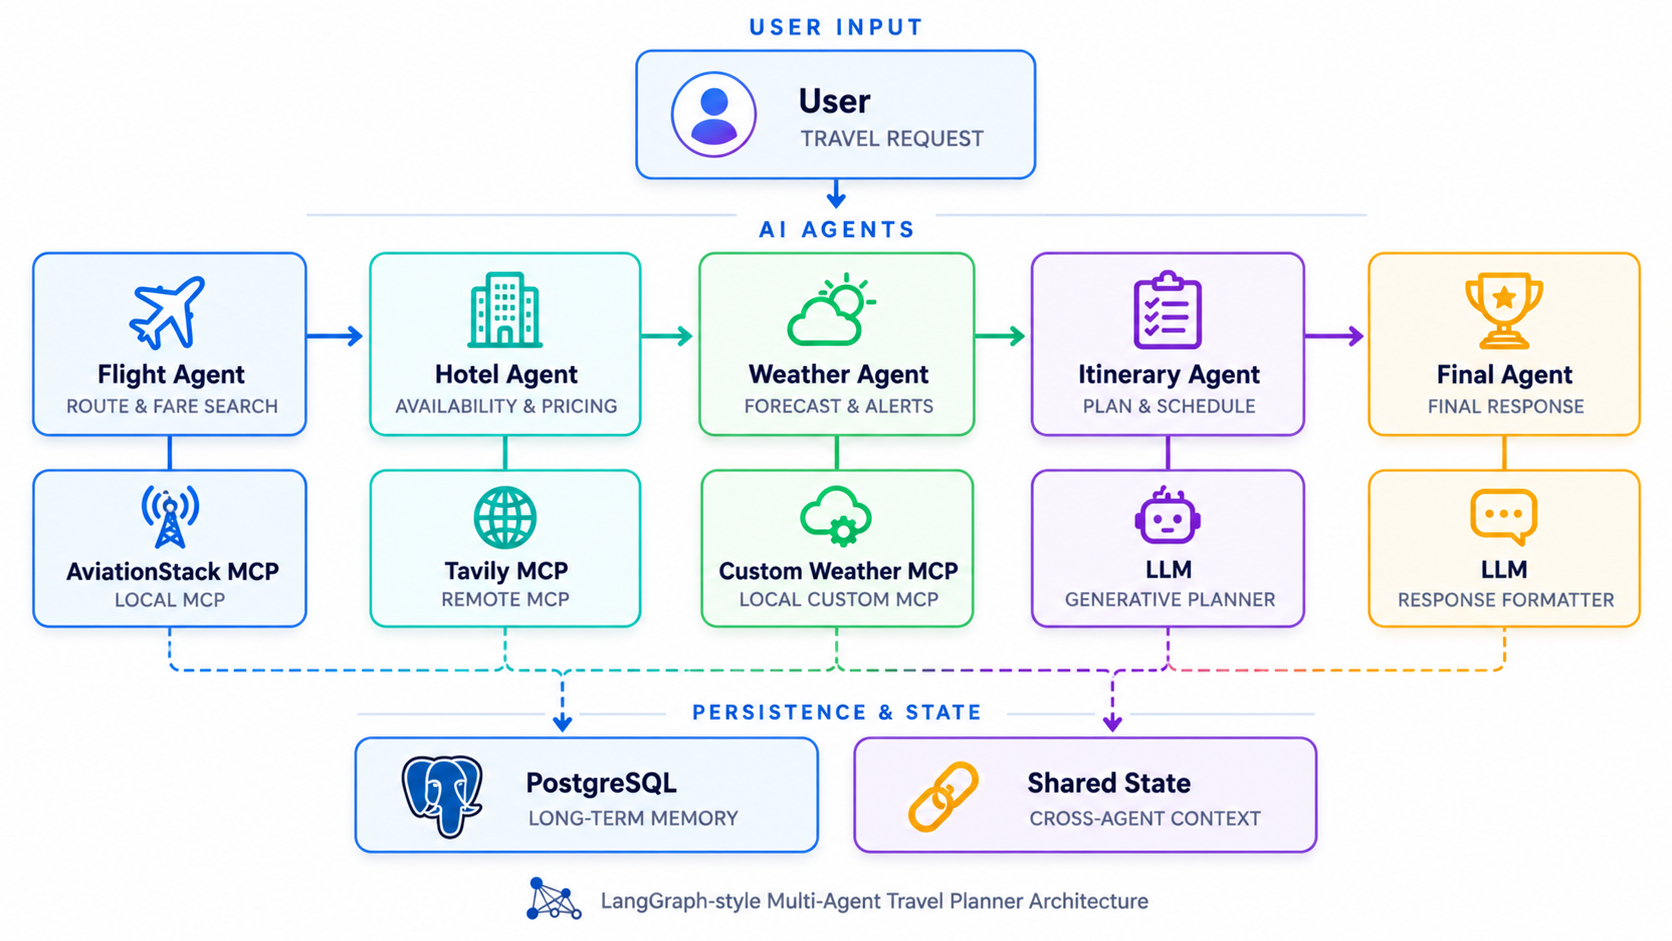

## MCP test 

In MCP (Model Context Protocol), we use stdio or streamable_http depending on how the MCP client communicates with the MCP server.

Both transports do exactly the same thing at the MCP level: they allow clients to discover tools, call tools, and receive results. The difference is how the messages travel between the client and server.

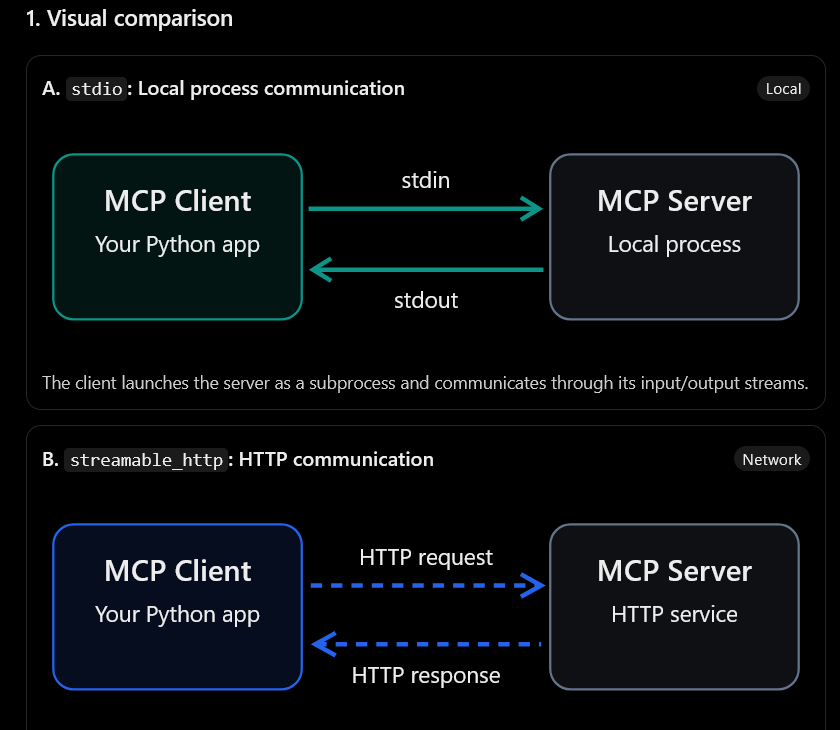

In our AI trip-planner project, you've already worked with three MCP servers:
- Weather MCP: Your custom Python server.
- AviationStack MCP: A locally launched server that accesses an external flight API.
- Tavily MCP: A remote MCP server accessed over HTTPS.
To understand these properly, we need to distinguish three different concepts:
1. Location: Where does the MCP server run?
2. Transport: How does your application communicate with it?
3. Service: What functionality does the MCP server provide?
These are independent choices. An MCP server can run on your computer and use HTTP, or it can run locally while accessing an external cloud service.

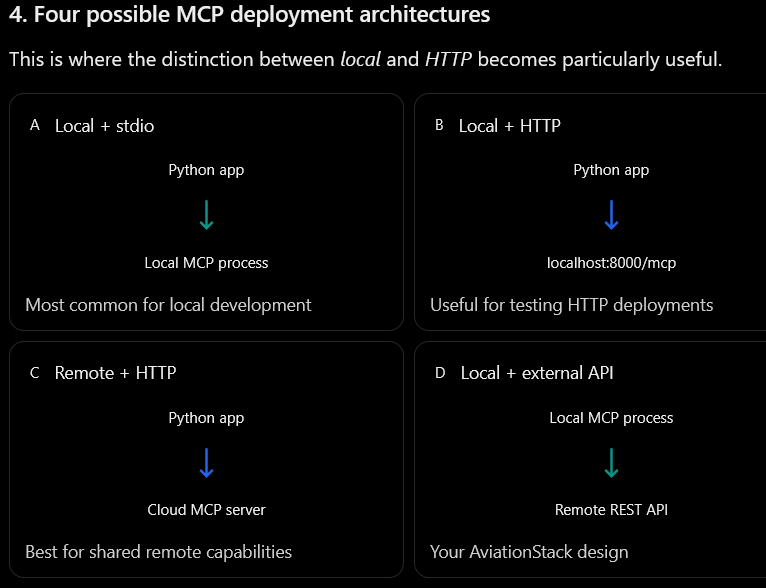

### Tavily MCP servert

In [ ]:
# Tavily MCP server test

import os
import nest_asyncio
from langchain_mcp_adapters.client import MultiServerMCPClient

nest_asyncio.apply()

TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")


client = MultiServerMCPClient(
    {
       "tavily": {
            "transport": "streamable_http",
            "url": f"https://mcp.tavily.com/mcp/?tavilyApiKey={TAVILY_API_KEY}"
        },
  
    }
)



async def get_all_tools():
    tools = await client.get_tools()
    print("\nAvailable MCP Tools:\n")

    for tool in tools:
        print(tool.name)

await get_all_tools()


Available MCP Tools:

tavily_search
tavily_extract
tavily_crawl
tavily_map
tavily_research


In [8]:
# This retuns tavily_search tool object
tavily_search_tool = None

async def get_tavily_search_tool():
    global tavily_search_tool
    if tavily_search_tool is not None:
        return

    tools = await client.get_tools()
    #print("\nAvailable MCP Tools:")

    #for tool in tools:
    #    print(tool.name)

    tavily_search_tool = next(
        tool
        for tool in tools
        if tool.name == "tavily_search"
    )



# This function can be used to call the tavily_search tool with a query in backend.py
async def tavily_mcp_search(query: str):
    await get_tavily_search_tool()
    result = await tavily_search_tool.ainvoke(
        {
            "query": query
        }
    )
    return result
    # print(result)

print(await tavily_mcp_search("What is the weather in Tehran (Iran)?"))

[{'type': 'text', 'text': '{"query":"What is the weather in Tehran (Iran)?","follow_up_questions":null,"answer":null,"images":[],"results":[{"url":"https://weathercity.com/ir/07/tehran","title":"Weather for Tehran, Tehran, Iran","content":"| 23°C 18°C | 21°C 16°C | | |  | | Tehran Detailed Weather Forecast |  | |  | | Saturday, October 24th, 2026 | | |  |  |  --- | | Overnight | Temperature: 21°C | | Mostly clear. | | | | |  |  |  --- | | Morning | Temperature: 21°C | | Mostly sunny. | | | | |  |  |  --- | | Afternoon | Temperature: 25°C | | Sunny. | | | | |  |  |  --- | | Evening | Temperature: 23°C | | Clear. Windy at times. | | | | Sunday, October 25th, 2026 | | |  |  |  --- | | Overnight | Temperature: 21°C | | Clear. | | | | [...] | | Clear. | | | | |  |  |  --- | | Morning | Temperature: 19°C | | Sunny. | | | | |  |  |  --- | | Afternoon | Temperature: 24°C | | Mostly sunny. | | | | |  |  |  --- | | Evening | Temperature: 23°C | | A mix of clear and cloudy skies. | | | | Monday, 

### Aviation MCP (to be run in .py code)

In [14]:
AVIATION_STACK_API_KEY = os.getenv("AVIATIONSTACK_API_KEY")

# Preserve the complete Windows environment when starting
# local stdio MCP servers.
AVIATION_ENV = os.environ.copy()
AVIATION_ENV["AVIATION_STACK_API_KEY"] = (
    AVIATION_STACK_API_KEY or ""
)


client = MultiServerMCPClient(
{
    "aviationstack": {
      "transport": "stdio",
      "command": "uvx",
      "args": [
        "aviationstack-mcp"
      ],
      "env": {
        "AVIATION_STACK_API_KEY": AVIATION_STACK_API_KEY
      }
    }
})

aviation_tools = {}


async def initialize_aviation_tools():
    global aviation_tools

    if aviation_tools:
        return

    # Load only AviationStack.
    # Tavily and Weather will not be initialized here.
    tools = await client.get_tools(
        server_name="aviationstack"
    )

    aviation_tools = {
        tool.name: tool
        for tool in tools
    }

    if not aviation_tools:
        raise RuntimeError(
            "AviationStack MCP connected but "
            "returned no tools."
        )

In [16]:
import os
import mcp.client.stdio as mcp_stdio

original_stdio_client = mcp_stdio.stdio_client

log_file = open("mcp_stderr.log", "w")

def patched_stdio_client(*args, **kwargs):
    kwargs.setdefault("errlog", log_file)
    return original_stdio_client(*args, **kwargs)

mcp_stdio.stdio_client = patched_stdio_client

In [ ]:
async def aviation_mcp_call(
    tool_name: str,
    tool_args: dict = None
):
    await initialize_aviation_tools()

    tool = aviation_tools.get(tool_name)

    if tool is None:
        available_tools = ", ".join(
            sorted(aviation_tools.keys())
        )

        raise ValueError(
            f"AviationStack tool '{tool_name}' "
            "was not found. "
            f"Available tools: "
            f"{available_tools or 'none'}"
        )

    result = await tool.ainvoke(
        tool_args or {}
    )

    return result

## Weather MCP

In [ ]:
from mcp.server.fastmcp import FastMCP
import requests
import os 
from dotenv import load_dotenv

load_dotenv()

mcp = FastMCP("Weather MCP Server")


OPENWEATHER_API_KEY = os.getenv("OPENWEATHER_API_KEY")


@mcp.tool()
def get_current_weather(city: str):

    response = requests.get(
        "https://api.openweathermap.org/data/2.5/weather",
        params={
            "q": city,
            "appid": OPENWEATHER_API_KEY,
            "units": "metric"
        }
    )

    data = response.json()

    if response.status_code != 200:
        return data

    return {
        "city": data["name"],
        "temperature_c": data["main"]["temp"],
        "feels_like_c": data["main"]["feels_like"],
        "humidity": data["main"]["humidity"],
        "condition": data["weather"][0]["description"],
        "wind_speed": data["wind"]["speed"]
    }



@mcp.tool()
def get_forecast(city: str):

    url = (
        "https://api.openweathermap.org/data/2.5/forecast"
    )

    params = {
        "q": city,
        "appid": OPENWEATHER_API_KEY,
        "units": "metric"
    }

    response = requests.get(
        url,
        params=params
    )

    data = response.json()

    forecast = []

    # Return first 5 forecast entries
    for item in data["list"][:5]:

        forecast.append(
            {
                "datetime": item["dt_txt"],
                "temperature": item["main"]["temp"],
                "weather": item["weather"][0]["description"]
            }
        )

    return {
        "city": city,
        "forecast": forecast
    }




if __name__ == "__main__":
    mcp.run()